In [1]:
import numpy as np
import matplotlib.pyplot as plt 
np.random.seed(78)


In [2]:
#Function Defitions 
def simulate_moran_process(N, initial_A, s=0.0, max_generations=None):
    
    if max_generations is None:
        max_generations = 10 * N**2

    N_A = initial_A
    generation = 0
    trajectory = [(generation, N_A)]

    while 0 < N_A < N and generation < max_generations:
        #calculate N_B based on inital_A
        N_B = N - N_A
        W = N_A * (1 + s) + N_B * 1.0 

        prob_A_reproduces = (N_A * (1 + s)) / W
        prob_B_reproduces = N_B / W

        prob_increase = prob_A_reproduces * (N_B / N)
        prob_decrease = prob_B_reproduces * (N_A / N)

        r = np.random.random()
        if r < prob_increase:
            N_A += 1
        elif r < prob_increase + prob_decrease:
            N_A -= 1

        generation += 1
        trajectory.append((generation, N_A))

    outcome = 1 if N_A == N else 0
    return outcome, trajectory


def theoretical_fixation_probability(N, i, s):
    # Exact Moran result: (1 - r^-i) / (1 - r^-N) with r = 1 + s
    if abs(s) < 1e-9:
        return i / N
    else:
        r = 1.0 + s
        numerator = 1.0 - r ** (-i)
        denom = 1.0 - r ** (-N)
        return numerator / denom


def run_fixation_study(N, initial_A, s, num_replicates):
    fixation_count = 0 #initaialize count 
    sample_trajectories = []
    generation_times = []

    for rep in range(num_replicates):
        outcome, trajectory = simulate_moran_process(N, initial_A, s)
        fixation_count += (outcome == 1)
        generation_times.append(len(trajectory) - 1)

        if rep < 200:
            sample_trajectories.append(trajectory)

    p_fix_empirical = fixation_count / num_replicates
    p_fix_theoretical = theoretical_fixation_probability(N, initial_A, s)
    se_empirical = np.sqrt(p_fix_empirical * (1 - p_fix_empirical) / num_replicates)

    #Store in directory
    results = {
        'N': N,
        'initial_A': initial_A,
        's': s,
        'Ns_product': N * s,
        'num_replicates': num_replicates,
        'fixation_count': fixation_count,
        'p_fix_empirical': p_fix_empirical,
        'p_fix_theoretical': p_fix_theoretical,
        'standard_error': se_empirical,
        'absolute_error': abs(p_fix_empirical - p_fix_theoretical),
        'mean_time': np.mean(generation_times),
        'trajectories': sample_trajectories
    }

    return results


def plot_trajectories(results, filename=None):
    N = results['N']
    trajectories = results['trajectories'][:200]

    fig, ax = plt.subplots(figsize=(12, 7))

    for trajectory in trajectories:
        times = [t for t, _ in trajectory]
        counts = [n_a for _, n_a in trajectory]
        final_count = counts[-1]
        color = 'green' if final_count == N else 'red'
        alpha = 0.6 if final_count == N else 0.4
        ax.plot(times, counts, color=color, alpha=alpha, linewidth=1.5)

    ax.axhline(y=N, color='darkgreen', linestyle='--', linewidth=2, label='Fixation (N={})'.format(N))
    ax.axhline(y=0, color='blue', linestyle='--', linewidth=2, label='Extinction')
    ax.set_xlabel('Birth-death steps (N steps = 1 generation)', fontsize=14)
    ax.set_ylabel('Number of A individuals', fontsize=14)
    ax.set_title('Moran Process Trajectories (N={}, s={})'.format(N, results["s"]), fontsize=16)
    ax.legend(fontsize=12)
    ax.grid(True, alpha=0.3)

    if filename:
        plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()


def print_results(all_results, s_values):
    # Print header
    print("\nFinal Results\n")
    header = "{:<8} {:<8} {:<12} {:<15} {:<15} {:<15}".format(
        's', 'N*s', 'Fixations', 'ρ_empirical', 'ρ_theoretical', 'Error_%'
    )
    print(header)
    print("-"*90)

    # Print each row
    for s in s_values:
        r = all_results[s]
        error_pct = (r['absolute_error']/r['p_fix_theoretical'])*100 if r['p_fix_theoretical'] > 0 else 0

        row = "{:<8.4f} {:<8.2f} {:<12} {:<15.4f} {:<15.4f} {:<15.2f}".format(
            s,
            r['Ns_product'],
            "{}/{}".format(r['fixation_count'], r['num_replicates']),
            r['p_fix_empirical'],
            r['p_fix_theoretical'],
            error_pct
        )
        print(row)

def plot_comparison(all_results, s_values):
    fig, ax = plt.subplots(figsize=(10, 6))
    
    empirical = [all_results[s]['p_fix_empirical'] for s in s_values]
    theoretical = [all_results[s]['p_fix_theoretical'] for s in s_values]
    errors = [all_results[s]['standard_error'] for s in s_values]
    
    ax.errorbar(s_values, empirical, yerr=errors, 
                marker='o', markersize=8, linewidth=2, capsize=5,
                label='Empirical (simulation)', color='blue')
    ax.plot(s_values, theoretical, 
            marker='s', markersize=8, linewidth=2,
            label='Theoretical (exact Moran)', color='red', linestyle='--')
    
    ax.set_xlabel('Selection coefficient (s)', fontsize=14)
    ax.set_ylabel('Fixation probability', fontsize=14)
    ax.set_title('Fixation Probability vs Selection Coefficient', fontsize=16)
    ax.legend(fontsize=12)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('Selection_effects.png', dpi=300, bbox_inches='tight')
    plt.show()




Hyperparameters:
  Population size (N): 50
  Initial A count: 1
  Replicates per condition: 2000
  Selection coefficients: [0.0, 0.01, 0.02, 0.05, 0.1]

Neutral Case: s=0.00
Empirical fixation probability:   0.0190
Theoretical (1/N):                 0.0200
Absolute error:                    0.0010
Standard error:                    0.0031


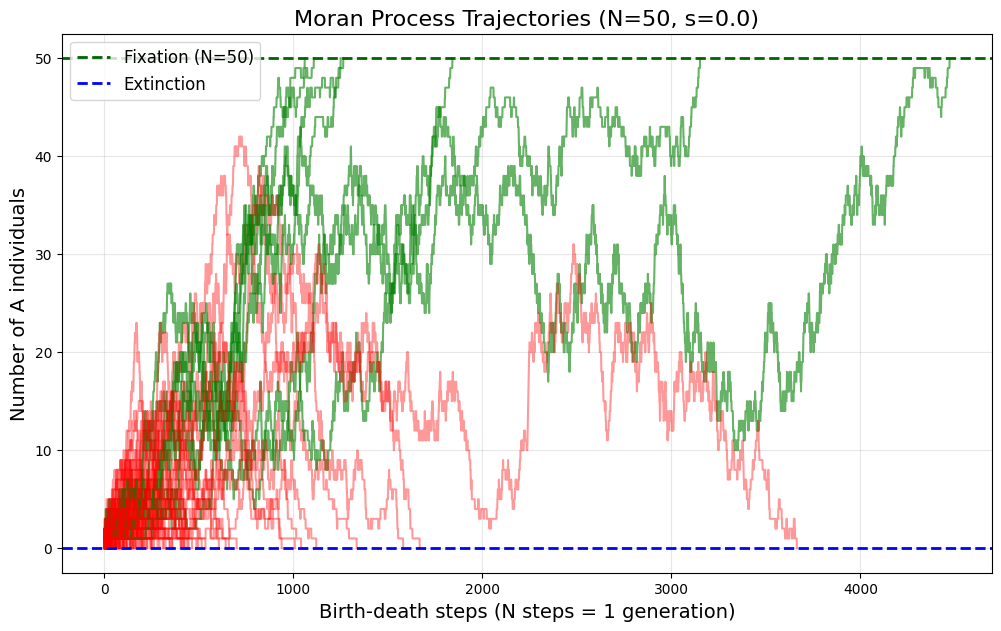


Selection Effects modeled via such individuals have probability to give birth and A individuals have probability (1+s))

Testing s = 0.000...
  Fixations: 41/2000
  ρ_fix_empirical = 0.0205, ρ_fix_theoretical = 0.0200

Testing s = 0.010...
  Fixations: 46/2000
  ρ_fix_empirical = 0.0230, ρ_fix_theoretical = 0.0253

Testing s = 0.020...
  Fixations: 59/2000
  ρ_fix_empirical = 0.0295, ρ_fix_theoretical = 0.0312

Testing s = 0.050...
  Fixations: 107/2000
  ρ_fix_empirical = 0.0535, ρ_fix_theoretical = 0.0522

Testing s = 0.100...
  Fixations: 176/2000
  ρ_fix_empirical = 0.0880, ρ_fix_theoretical = 0.0917

Final Results

s        N*s      Fixations    ρ_empirical     ρ_theoretical   Error_%        
------------------------------------------------------------------------------------------
0.0000   0.00     41/2000      0.0205          0.0200          2.50           
0.0100   0.50     46/2000      0.0230          0.0253          8.95           
0.0200   1.00     59/2000      0.0295      

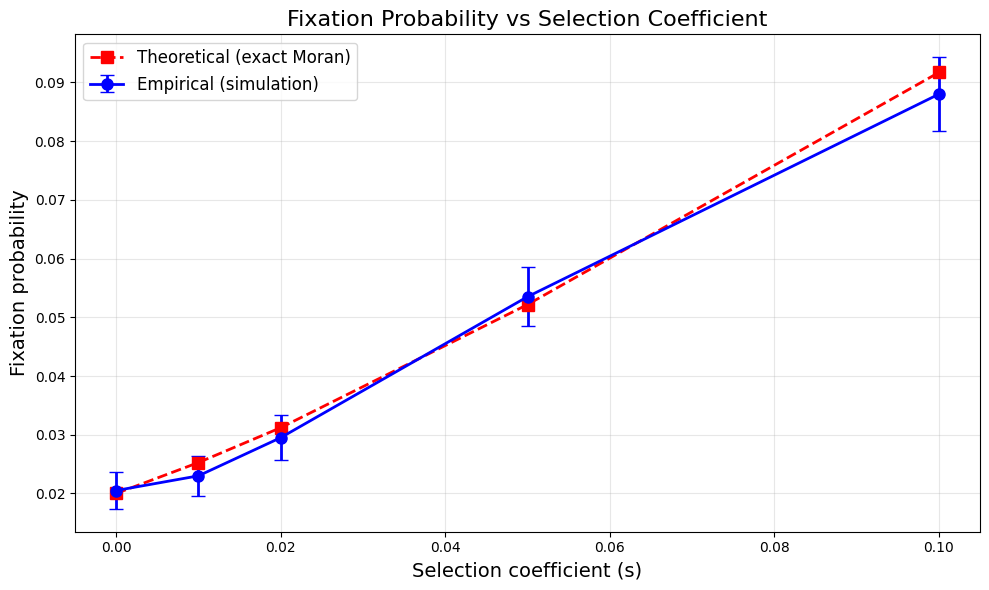

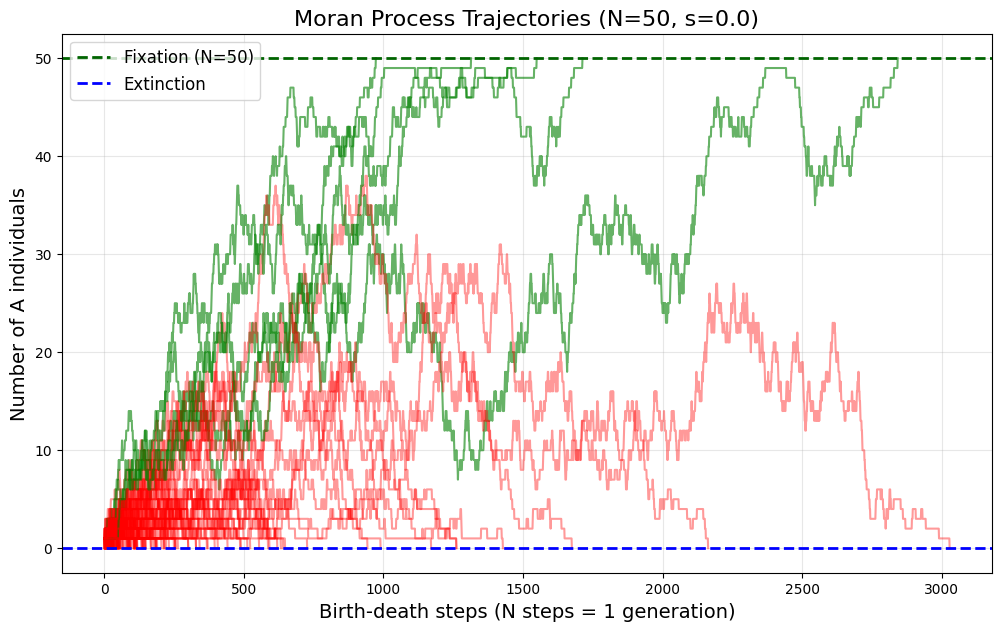

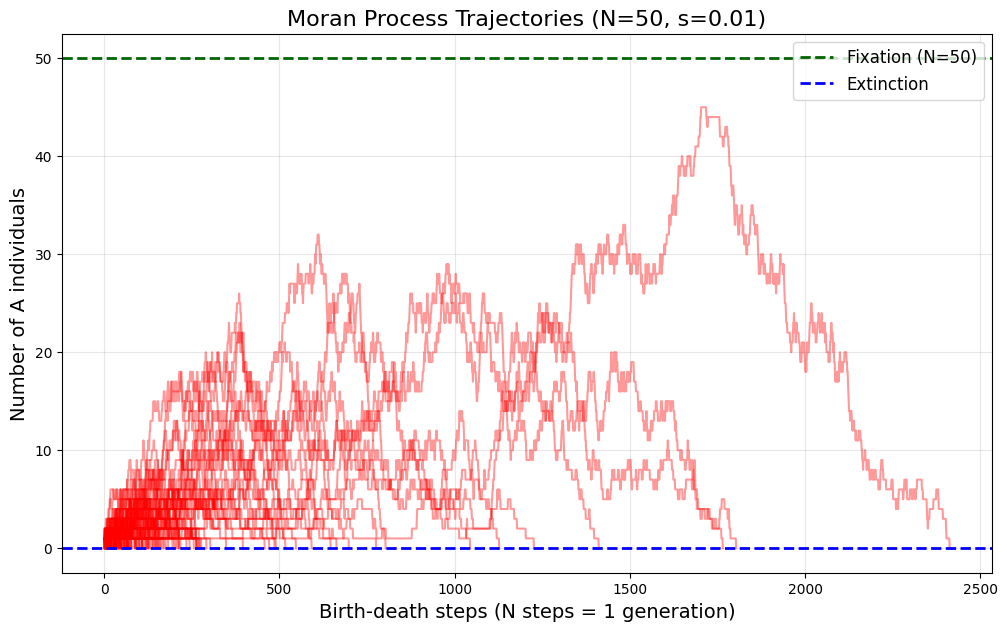

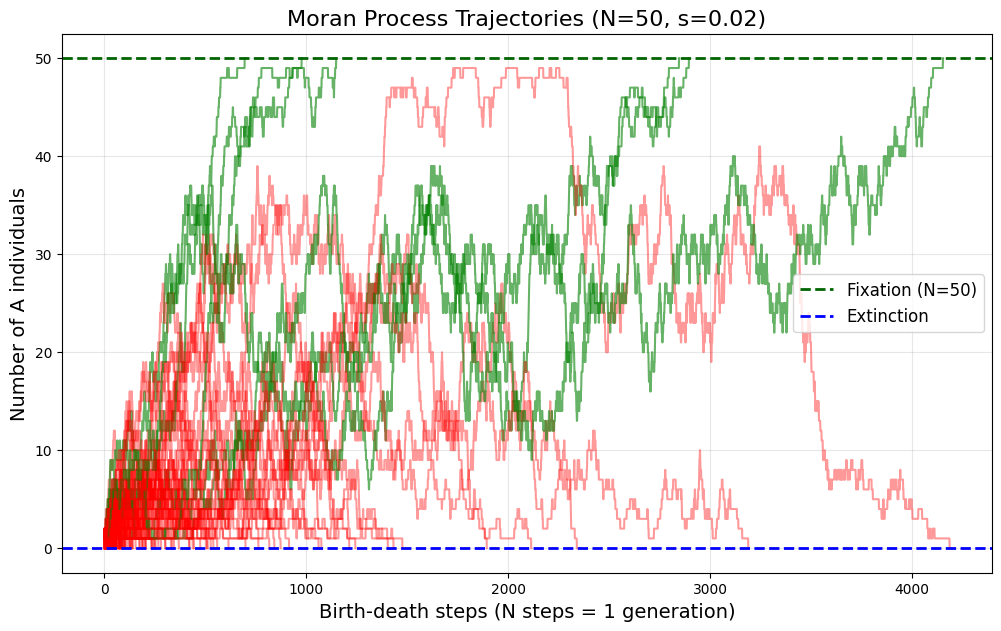

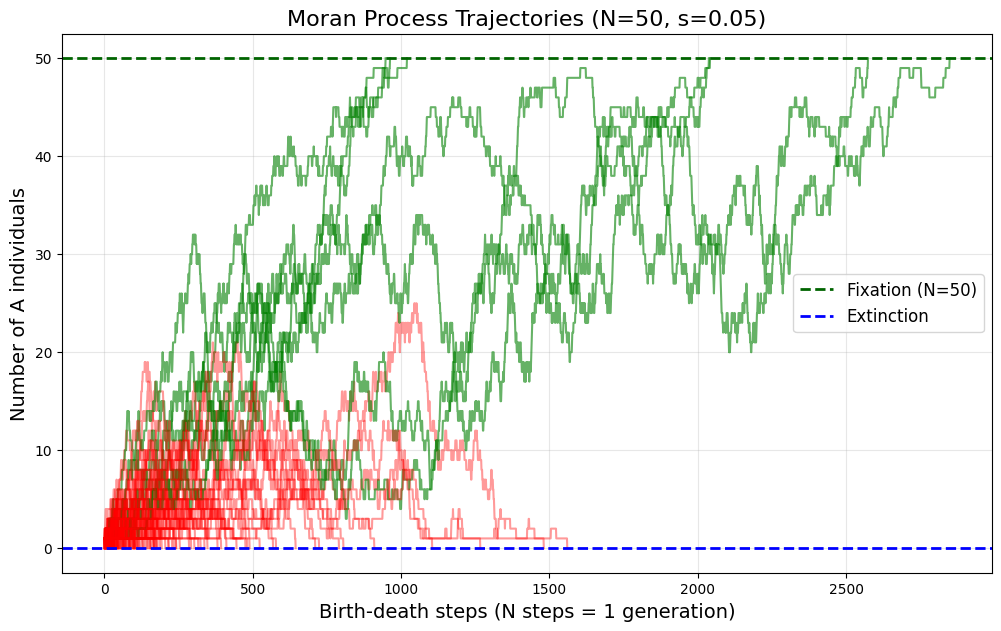

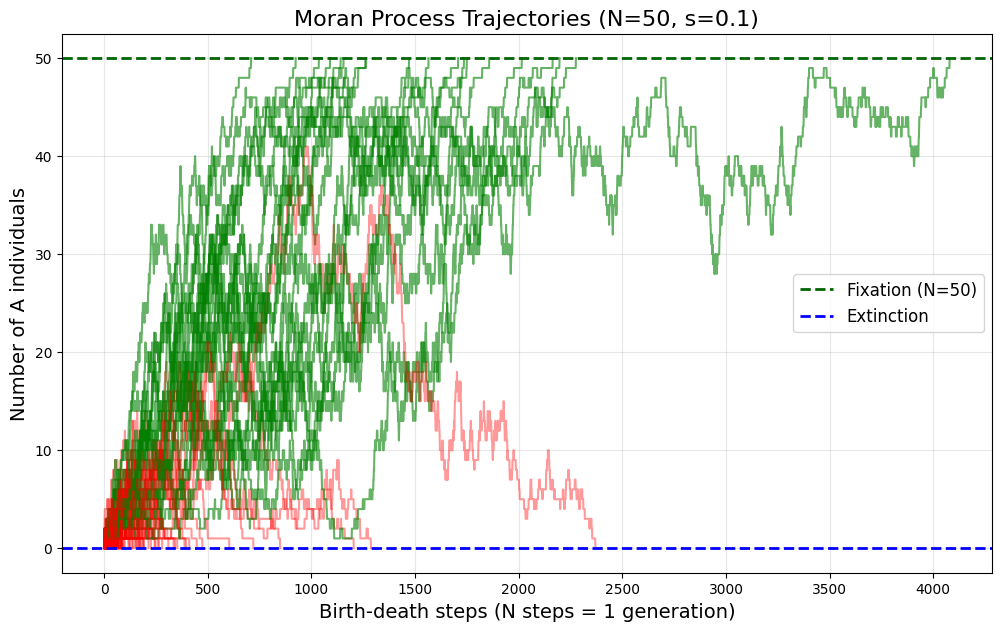

In [3]:
#Execution 

# Hyperparameters
N = 50
initial_A = 1
num_replicates = 2000
s_values = [0.0, 0.01, 0.02, 0.05, 0.1]

print("\nHyperparameters:")
print("  Population size (N): {}".format(N))
print("  Initial A count: {}".format(initial_A))
print("  Replicates per condition: {}".format(num_replicates))
print("  Selection coefficients: {}".format(s_values))

# Part (a): Neutral case
results_neutral = run_fixation_study(N, initial_A, 0.0, num_replicates)
print("\nNeutral Case: s=0.00")
print("Empirical fixation probability:   {:.4f}".format(results_neutral['p_fix_empirical']))
print("Theoretical (1/N):                 {:.4f}".format(results_neutral['p_fix_theoretical']))
print("Absolute error:                    {:.4f}".format(results_neutral['absolute_error']))
print("Standard error:                    {:.4f}".format(results_neutral['standard_error']))

plot_trajectories(results_neutral, 'moran_neutral_trajectories.png')

# Part (b): Selection effects
print("\nSelection Effects modeled via such individuals have probability to give birth and A individuals have probability (1+s))")
all_results = {}
#
for s in s_values:
    print("\nTesting s = {:.3f}...".format(s))
    results = run_fixation_study(N, initial_A, s, num_replicates)
    all_results[s] = results
    print("  Fixations: {}/{}".format(results['fixation_count'], num_replicates))
    print("  ρ_fix_empirical = {:.4f}, ρ_fix_theoretical = {:.4f}".format(
        results['p_fix_empirical'], results['p_fix_theoretical']
    ))    

# Final results 
print_results(all_results, s_values)

#Visualize effect of the benifit of s in compaison to s=0.0(neutral)
plot_comparison(all_results, s_values)

#Trajectories for b per s to see how much more likley to reach fixation visually another way 
for s in s_values:
    plot_trajectories(all_results[s], 'trajectories_s_{:.2f}.png'.format(s))
